# Is the CRScore human-rated data suitable for training the comment-substance scorer? (analysis before any training)

Data: the phase-2 human study of CRScore (MIT). People rated code review comments from 1 to 5 on **conciseness**, **comprehensiveness** and **relevance**. About 90% of the rated comments were written by nine
models and about 10% (`msg`) are the original human reviewer comments. Questions answered here, in order, before a scorer is trained:

1. How many ratings are there and how are they spread (is there something to learn)?
2. How reliable are the ratings (how well do two people agree; this is the ceiling for any model)?
3. Do the model-written comments leak "who wrote it" into the ratings (would a scorer learn the writer's style instead of substance)?
4. Does comment length alone explain the ratings (length bias)?
5. How much signal does plain text carry (a cheap pilot, grouped by diff), including the transfer from model-written to human-written comments?
6. Is the number of human-written comments enough (learning curve)?

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("../../helpers").resolve()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
import crscore, substance
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 170)
d = crscore.load_main(); pairs = crscore.load_pairs()
d["words"] = d.clean.str.split().str.len()
print("rated comments:", len(d), "| human-written:", int(d.human.sum()), "| diffs:", d.group.nunique(), "| comments rated by both annotators:", len(pairs))
display(d.groupby("system").agg(n=("rel", "size"), rel=("rel", "mean"), comp=("comp", "mean"), con=("con", "mean"), words=("words", "median")).round(2).sort_values("rel"))

rated comments: 2775 | human-written: 290 | diffs: 291 | comments rated by both annotators: 264


,n,rel,comp,con,words
system,,,,,
knn_pred,291,1.07,1.04,1.12,14.0
lstm_pred,291,1.21,1.14,1.42,9.0
stable_code_pred,291,1.69,1.55,2.29,15.0
codereviewer_pred,291,1.92,1.68,3.06,5.0
msg,290,2.13,1.88,3.05,14.0
codellama_13b_pred,157,2.16,2.15,2.47,51.0
magicoder_pred,291,2.34,2.25,2.97,35.0
deepseekcoder_pred,291,2.52,2.26,3.44,22.0
llama3_pred,291,2.62,2.35,3.44,32.0


## 1. Spread of the ratings

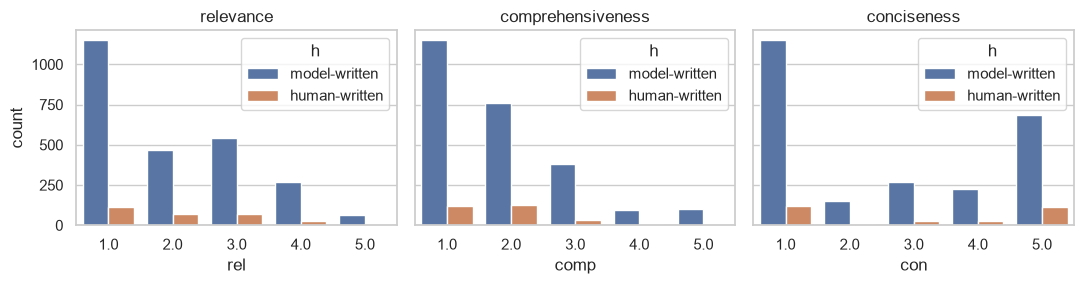

Spearman between the three ratings:


,rel,comp,con
rel,1.00,0.96,0.92
comp,0.96,1.00,0.86
con,0.92,0.86,1.00


share of ratings at 1 / at 5: {'rel': (np.float64(0.46), np.float64(0.03)), 'comp': (np.float64(0.46), np.float64(0.04)), 'con': (np.float64(0.46), np.float64(0.29))}


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for a, c in zip(ax, ("rel", "comp", "con")):
    sns.countplot(data=d.assign(h=d.human.map({True: "human-written", False: "model-written"})), x=c, hue="h", ax=a); a.set_title({"rel": "relevance", "comp": "comprehensiveness", "con": "conciseness"}[c])
fig.tight_layout(); plt.show()
print("Spearman between the three ratings:"); display(d[["rel", "comp", "con"]].corr(method="spearman").round(2))
print("share of ratings at 1 / at 5:", {c: (round((d[c] == 1).mean(), 2), round((d[c] == 5).mean(), 2)) for c in ("rel", "comp", "con")})

## 2. Reliability of the ratings (the ceiling)

The four agreement files hold comments rated by both annotators. Quadratic-weighted kappa and Spearman measure how well two people agree; ICC(2,1) is the usual reliability figure. A model cannot be expected to
agree with a person better than people agree with each other.

In [3]:
import sys
sys.path.insert(0, str(Path("../../../../ml_lib").resolve()))
from core import qwk, icc
rows = {}
for c, name in (("rel", "relevance"), ("comp", "comprehensiveness"), ("con", "conciseness")):
    a, m = pairs[c + "_a"].to_numpy(float), pairs[c + "_m"].to_numpy(float)
    rows[name] = {"pairs": len(a), "Spearman": spearmanr(a, m)[0], "weighted kappa": qwk(a.astype(int), m.astype(int)), "ICC(2,1)": icc(a, m, 2), "exact agreement": float((a == m).mean()), "within 1": float((abs(a - m) <= 1).mean())}
rel = pd.DataFrame(rows).T; display(rel.round(2))
h = pairs[pairs.system == "msg"]; print("human-written comments rated by both:", len(h))
print("ceiling for a perfect predictor against one rater (about sqrt of the reliability):", {k: round(float(np.sqrt(max(v, 0))), 2) for k, v in rel["ICC(2,1)"].items()})
display(d.groupby(["rater"]).agg(rel=("rel", "mean"), comp=("comp", "mean"), con=("con", "mean")).round(2).rename_axis("rater leniency"))

,pairs,Spearman,weighted kappa,"ICC(2,1)",exact agreement,within 1
relevance,264.0,0.80,0.80,0.80,0.68,0.94
comprehensiveness,264.0,0.77,0.79,0.79,0.74,0.93
conciseness,264.0,0.81,0.80,0.80,0.69,0.89


human-written comments rated by both: 35
ceiling for a perfect predictor against one rater (about sqrt of the reliability): {'relevance': 0.9, 'comprehensiveness': 0.89, 'conciseness': 0.9}


,rel,comp,con
rater leniency,,,
atharva,1.91,1.88,2.53
marcus,2.19,1.88,2.88


## 3. Does the writer's style leak into the ratings?

If most of the variance in the ratings is explained by *which model wrote the comment*, a scorer can earn its score by recognising the writer's style. A scorer that does well on model-written comments but not on human ones
would be no use for students.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
gm = d.rel.mean(); ss_tot = ((d.rel - gm) ** 2).sum()
r2_sys = 1 - ((d.rel - d.groupby("system").rel.transform("mean")) ** 2).sum() / ss_tot
print(f"share of the variance of relevance explained by the writer (system) alone: {r2_sys:.2f}")
y_h = d.human.astype(int).to_numpy(); oof = np.zeros(len(d))
for tr, te in GroupKFold(5).split(d, groups=d.group):
    m = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=2, max_iter=2000, class_weight="balanced")).fit(d.clean.iloc[tr], y_h[tr])
    oof[te] = m.predict_proba(d.clean.iloc[te])[:, 1]
print(f"can text alone tell a human-written comment from a model-written one? AUC {roc_auc_score(y_h, oof):.2f} (0.5 = no)")

share of the variance of relevance explained by the writer (system) alone: 0.25


can text alone tell a human-written comment from a model-written one? AUC 0.88 (0.5 = no)


## 4. Length bias

In [5]:
rows = []
for name, sub in (("all comments", d), ("human-written only", d[d.human]), ("model-written only", d[~d.human])):
    rows.append({"subset": name, "n": len(sub), **{c: spearmanr(sub.words, sub[c])[0] for c in ("rel", "comp", "con")}})
display(pd.DataFrame(rows).set_index("subset").round(2).rename(columns={"rel": "Spearman(words, relevance)", "comp": "Spearman(words, comprehensiveness)", "con": "Spearman(words, conciseness)"}))

,n,"Spearman(words, relevance)","Spearman(words, comprehensiveness)","Spearman(words, conciseness)"
subset,,,,
all comments,2775,0.30,0.35,0.13
human-written only,290,0.14,0.19,-0.00
model-written only,2485,0.32,0.37,0.15


## 5. A cheap learnability pilot (not the real training)

Ridge regression on (a) length, (b) TF-IDF, (c) MiniLM embeddings, predicting relevance, with five folds **grouped by diff**. Scores: Spearman with the human rating, on all comments and on the
human-written ones only, plus the transfer test: train on model-written comments only, test on human-written ones.

In [6]:
E = substance.embed("MiniLM", d.clean.tolist())
y = d.rel.to_numpy(float); g = d.group.to_numpy(); hmask = d.human.to_numpy()
def feats(kind, tr, te):
    if kind == "length":
        f = lambda ix: np.log1p(d.words.iloc[ix].to_numpy())[:, None]; return f(tr), f(te)
    if kind == "TF-IDF":
        v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(d.clean.iloc[tr]); return v.transform(d.clean.iloc[tr]), v.transform(d.clean.iloc[te])
    return E[tr], E[te]
res = {}
for kind in ("length", "TF-IDF", "MiniLM embeddings"):
    oof = np.zeros(len(d))
    for tr, te in GroupKFold(5).split(d, groups=g):
        Xtr, Xte = feats(kind, tr, te); oof[te] = Ridge(alpha=1.0 if kind != "TF-IDF" else 3.0).fit(Xtr, y[tr]).predict(Xte)
    tr = np.where(~hmask)[0]; te = np.where(hmask)[0]; Xtr, Xte = feats(kind, tr, te); tp = Ridge(alpha=1.0 if kind != "TF-IDF" else 3.0).fit(Xtr, y[tr]).predict(Xte)
    res[kind] = {"all comments (CV)": spearmanr(y, oof)[0], "human-written only (CV)": spearmanr(y[hmask], oof[hmask])[0], "train model-written -> test human-written": spearmanr(y[hmask], tp)[0]}
pilot = pd.DataFrame(res).T; display(pilot.round(2))

,all comments (CV),human-written only (CV),train model-written -> test human-written
length,0.29,0.14,0.14
TF-IDF,0.48,0.06,0.08
MiniLM embeddings,0.37,0.08,0.11


## 6. Is the number of human-written comments enough? (learning curve, MiniLM + Ridge, human-written only)

In [7]:
hi = np.where(hmask)[0]; rng = np.random.default_rng(1); rows = []
for n in (40, 80, 120, 160, 200):
    sc = []
    for r in range(30):
        pick = rng.permutation(hi); tr, te = pick[:n], pick[n:]
        if len(te) < 20: continue
        sc.append(spearmanr(y[te], Ridge(alpha=1.0).fit(E[tr], y[tr]).predict(E[te]))[0])
    rows.append({"human-written training comments": n, "Spearman on the rest": np.mean(sc), "sd": np.std(sc)})
display(pd.DataFrame(rows).set_index("human-written training comments").round(2))

,Spearman on the rest,sd
human-written training comments,,
40,0.05,0.06
80,0.05,0.05
120,0.07,0.06
160,0.10,0.06
200,0.09,0.09


## 7. Reading the results

**Verdict: the ratings are good, but this data is not suitable for training a text-only scorer that has to work on human-written comments. A model trained on it would look fine on its own cross-validation and would not transfer. I would not expect better results than before.**

**What is good.**
- 2,775 rated comments (1,403 rated 1 for relevance, 3% rated 5), so the scale is used and there is something to learn.
- The ratings are reliable: two annotators agree with ICC 0.80 on relevance, comprehensiveness and conciseness (exact agreement 68-74%, within one point 89-94%, on 264 doubly rated comments). A perfect predictor could reach about 0.9 correlation with a single rater, so the labels are not the limit.
- Relevance, comprehensiveness and conciseness correlate 0.86-0.96, so one number (relevance) is enough.

**What is wrong for our purpose.**
1. **The comments are 90% model-written (2,485 of 2,775; 290 are human).** The writer alone explains 25% of the variance of relevance, and a plain text model can tell human from model comments with AUC 0.88. A scorer can earn credit by recognising the writer's style.
2. **Length bias.** In the model-written comments, longer is rated better (Spearman 0.32 with relevance); in the human-written ones it is weak (0.14). A scorer trained mostly on model-written text learns "longer is better".
3. **The pilot shows it does not transfer.** Ridge on text, five folds grouped by diff, Spearman with relevance: TF-IDF 0.48, MiniLM 0.37, length alone 0.29 over all comments, but **0.06 to 0.14 on the human-written ones**, and 0.08 to 0.14 when trained on model-written comments and tested on human-written ones. A learning curve on the 290 human-written comments alone stays near 0.05-0.10 up to 200 training comments, so more of them would not obviously fix it.
4. **Relevance is judged against the code change.** The raters saw the diff and the claims about it. Text alone cannot say whether a comment is relevant to code it does not contain.

**What would make a dataset suitable.** Mostly human-written comments, with the code change as an input (a model that reads comment and diff together), or labels that depend on the comment itself (specific, explains why, gives a fix) and not on the diff.

**Use of this data.** The 290 human-written, doubly checked comments are still a valid small test set to compare scorers, and the human-agreement figures (ICC 0.80) are a useful ceiling to cite.